# 05 · Sparse vs shaped reward

The project's scientific objective includes "reward designs that make optimizing sparse goals feasible". Here we train the same
five methods with three rewards that encode the same goal (an exact 5-7-5 haiku) with decreasing density, and we check a
property of GPOMDP that depends on the reward being spread over time.

Structure: **setup** (the three reward designs, how rare success is) → **GPOMDP = REINFORCE under a terminal reward** (derivation and
checks) → **training** (tuning and final runs, same protocol as notebook 04) → **why the sparse runs behave as they do** →
**discussion**.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from poet import experiments as X, protocol as P, evaluate as ev, estimators as E, train, stats, variance as Vr
from poet.estimators import LABELS
from poet.haiku import TARGETS
from poet.policy import TabularSoftmax, rollout

plt.rcParams['figure.dpi'] = 110
COLORS = {m: f'C{k}' for k, m in enumerate(P.METHODS)}
DESIGNS = ['shaped', 'lines', 'sparse']
envs = {d: X.make_env({'reward': P.REWARD_DESIGNS[d]}) for d in DESIGNS}
TARGET_VALID = json.load(open(X.RESULTS_DIR / '04_target.json'))['valid_target']
for d in DESIGNS:
    print(f'{d:7s}', envs[d].cfg)

shaped  RewardConfig(syllable_weight=1.0, exact_line_bonus=3.0, poem_bonus=10.0, fluency_weight=0.03, repeat_penalty=2.0, overflow_penalty=1.0, progress=True, kl_coef=0.5, sparse=False)
lines   RewardConfig(syllable_weight=0.0, exact_line_bonus=1.0, poem_bonus=1.0, fluency_weight=0.0, repeat_penalty=0.0, overflow_penalty=0.0, progress=False, kl_coef=0.0, sparse=False)
sparse  RewardConfig(syllable_weight=1.0, exact_line_bonus=3.0, poem_bonus=10.0, fluency_weight=0.03, repeat_penalty=2.0, overflow_penalty=1.0, progress=True, kl_coef=0.5, sparse=True)


## 1. Three rewards for the same goal

| design | reward | when it is non-zero |
|---|---|---|
| **shaped** (notebooks 03–04) | per-word syllable progress, exact-line bonus 3, completion bonus 10, fluency, repeat and overflow penalties, KL to the bigram (η = 0.5) | every step |
| **lines** | +1 when a line ends with exactly its target, +1 more when the poem is a valid 5-7-5 | at the 3 line ends |
| **sparse** | 1 if the poem is a valid 5-7-5, else 0 | only at the last step |

The KL penalty is used only with the shaped reward. It is itself a per-step reward, so adding it would make the other two designs dense.

All three are maximised by the same policies (always write a valid haiku), so we compare them on a common scale: the
**valid 5-7-5 rate** on fresh poems, with the valid-rate target 0.8 fixed in notebook 04.

**How rare is success?** Under the untrained bigram each line starts from `<s>` and the policy depends only on the previous word, so the
three lines are independent and $P(\text{valid}) = p_5^2\,p_7$, where $p_k$ is the probability that a line hits exactly $k$ syllables.

In [2]:
env = envs['shaped']
pol0 = TabularSoftmax(env.bigram_logits(1.0), 1.0)
exact = {0: [], 1: [], 2: []}
for tr in ev.sample_poems(env, pol0, 20_000, np.random.default_rng(0)):
    s = env.reset()
    for a in tr.actions:
        line = s[1]
        s, info = env.transition(s, a)
        if info['line_end']:
            exact[line].append(info['line_exact'])
p = {line: np.mean(v) for line, v in exact.items()}
p_valid = p[0] * p[1] * p[2]
print(f'P(exact line): line 1 (5) {p[0]:.3f}, line 2 (7) {p[1]:.3f}, line 3 (5) {p[2]:.3f}   (20 000 bigram poems)')
print(f'P(valid poem) = {p_valid:.2e}  ->  about one valid poem every {1 / p_valid:,.0f} episodes')

P(exact line): line 1 (5) 0.052, line 2 (7) 0.044, line 3 (5) 0.045   (20 000 bigram poems)
P(valid poem) = 1.02e-04  ->  about one valid poem every 9,798 episodes


## 2. With a terminal reward, GPOMDP *is* REINFORCE

GPOMDP multiplies the score of step $h$ by the reward-to-go, while REINFORCE multiplies it by the whole
return:

$$\hat g_{\text{GPOMDP}} = \frac1n\sum_i\sum_h \nabla\log\pi(A^i_h\mid S^i_h)\sum_{t\ge h} r^i_t,
\qquad \hat g_{\text{REINFORCE}} = \frac1n\sum_i\sum_h \nabla\log\pi(A^i_h\mid S^i_h)\sum_{t\ge 0} r^i_t .$$

They differ only in the rewards $r_t$ with $t<h$, which GPOMDP drops because an action cannot affect rewards received before it.
With the **sparse** reward, every $r_t$ is zero except at the last step of the episode, and the last step comes after every action
($t = L-1 \ge h$). So every reward-to-go equals $R(\tau)$, and the two estimators are **the same function of the batch**, not just
equal in expectation. GPOMDP's variance reduction comes entirely from dropping *earlier* rewards, so it needs rewards that arrive
before the end of the episode. The denser the reward, the more there is to drop.

With baselines the two still differ, even under the sparse reward. REINFORCE + $b$ subtracts one number per episode. GPOMDP + $b_t$
subtracts $\sum_{t\ge h} b_t$, which depends on $h$ and on *when* the other episodes of the batch ended.

**Check 1: identical gradients on identical batches.** We need a policy that writes valid poems often enough for the sparse reward to be
non-zero, so we first train with the shaped reward until at least 30% of its poems are valid (checked every 250 episodes, so it overshoots). We then draw batches with that policy and
compute both estimators on each batch, under each reward.

In [3]:
# A partially trained policy: shaped reward, GPOMDP + b_t, alpha = 3, trained in chunks of 250 episodes until valid >= 0.3
pol = X.make_policy(env, {})
rng = np.random.default_rng(0)
episodes = 0
while True:
    train.train_batch_pg(env, pol, 'gpomdp_b', 3.0, 10, 250, rng)
    episodes += 250
    valid = ev.poem_metrics(env, ev.sample_poems(env, pol, 300, np.random.default_rng(1)))['valid']
    if valid >= 0.3:
        break
print(f'policy after {episodes} training episodes: valid rate {valid:.2f}')

rng = np.random.default_rng(5)
for d in DESIGNS:
    e = envs[d]
    diffs, norms = [], []
    for _ in range(50):
        batch = [rollout(e, pol, rng) for _ in range(10)]
        g1, g2 = E.reinforce(batch, 1.0), E.gpomdp(batch, 1.0, e.horizon)
        diffs.append(max(np.abs(g1[s] - g2[s]).max() for s in g1))
        norms.append(np.sqrt(Vr.sq_norm(g1)))
    print(f'{d:7s} max |REINFORCE - GPOMDP| over 50 batches = {max(diffs):.3g}   (typical |REINFORCE| = {np.median(norms):.3g})')

policy after 3500 training episodes: valid rate 0.73


shaped  max |REINFORCE - GPOMDP| over 50 batches = 1.19   (typical |REINFORCE| = 2.18)


lines   max |REINFORCE - GPOMDP| over 50 batches = 0.387   (typical |REINFORCE| = 1)


sparse  max |REINFORCE - GPOMDP| over 50 batches = 0   (typical |REINFORCE| = 0.16)


**Check 2: variance of the four estimators at this policy, under each reward.** $M = 400$ independent batches of $n = 10$ episodes.
All four estimators are computed on the same batches, and we report the total variance $\operatorname{tr}\operatorname{Cov}[\hat g]$ (summed
over all table entries). The scale of the three rewards is different, so compare the *ratios within a column*, not the numbers across
columns.

In [4]:
var = {d: Vr.estimator_variance(envs[d], pol, E.METHODS, 10, 400, np.random.default_rng(11)) for d in DESIGNS}
print(f'{"estimator":24s}' + ''.join(f'{d:>22s}' for d in DESIGNS))
for m in E.METHODS:
    print(f'{LABELS[m]:24s}' + ''.join(f'{var[d][m]["total_var"]:13.4g} ({var[d][m]["total_var"] / var[d]["reinforce"]["total_var"]:5.2f}x)' for d in DESIGNS))
print('(in brackets: variance relative to REINFORCE under the same reward)')

estimator                               shaped                 lines                sparse
REINFORCE                       7.449 ( 1.00x)        1.124 ( 1.00x)      0.02927 ( 1.00x)
REINFORCE + baseline            7.861 ( 1.06x)        0.833 ( 0.74x)       0.1274 ( 4.35x)
GPOMDP                          6.512 ( 0.87x)       0.4411 ( 0.39x)      0.02927 ( 1.00x)
GPOMDP + baseline b_t           12.59 ( 1.69x)       0.6092 ( 0.54x)       0.1223 ( 4.18x)
(in brackets: variance relative to REINFORCE under the same reward)


Under the sparse reward the baselines make the variance about four times *larger*. A constant baseline can only help if the size of
the score $\sum_h\nabla\log\pi(A_h\mid S_h)$ is roughly the same whatever the return is. At this policy, that assumption fails badly.
We compare the squared norm of the trajectory score for valid and invalid poems:

In [5]:
from poet.policy import add_score
rng = np.random.default_rng(12)
norms = {True: [], False: []}
for _ in range(2000):
    tr = rollout(envs['sparse'], pol, rng)
    g = {}
    for s, a, p in zip(tr.states, tr.actions, tr.probs):
        add_score(g, s, p, a, 1.0, 1.0)
    norms[tr.task_ret > 0].append(Vr.sq_norm(g))
for ok in (True, False):
    print(f'{"valid" if ok else "invalid":7s} poems: {len(norms[ok]):4d} of 2000, mean ||score||^2 = {np.mean(norms[ok]):.2f}')

valid   poems: 1416 of 2000, mean ||score||^2 = 0.43
invalid poems:  584 of 2000, mean ||score||^2 = 8.29


**Check 3: identical training runs.** The identity also holds along a whole training run. Before the first update, REINFORCE and GPOMDP
runs with the same seed see the same episodes. Under the sparse reward they then compute the same gradient, so they take the same
step, and so on. The tuning runs of §3 used the same seeds for both methods, so their learning curves must be identical under the sparse
reward, and not under the other two.

In [6]:
TUNE_CACHE = X.RESULTS_DIR / '05_tuning.pkl'
GRID0 = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]          # notebook 04's final grid
def tune_spec(m, a, s, d):
    return P.spec(m, a, s, reward=P.REWARD_DESIGNS[d])
for d in ['sparse', 'lines']:
    # these runs are part of the tuning of §3: computed here if the cache is empty, and reused there
    specs = [tune_spec(m, a, s, d) for a in GRID0 for s in P.TUNE_SEEDS for m in ('reinforce', 'gpomdp')]
    runs = X.run_many(specs, TUNE_CACHE, verbose=False)
    same = []
    for r1, r2 in zip(runs[0::2], runs[1::2]):
        h1, h2 = r1['history'], r2['history']
        same.append(h1['eval_return'] == h2['eval_return'] and h1['train_return'] == h2['train_return'])
    print(f'{d:7s}: REINFORCE and GPOMDP runs identical in {sum(same)}/{len(same)} (alpha, seed) pairs')

sparse : REINFORCE and GPOMDP runs identical in 21/21 (alpha, seed) pairs


lines  : REINFORCE and GPOMDP runs identical in 0/21 (alpha, seed) pairs


## 3. Training with each reward

Same protocol as notebook 04: budget $10^5$ episodes, 3 tuning seeds per grid value, the tuning criterion is the mean evaluation return
over the budget, and the grid is extended for all methods when a best α is at an edge. The rewards have very different scales (a valid
poem is worth about 34 under the shaped reward, 4 under *lines*, 1 under *sparse*), so each design is tuned separately, starting from
notebook 04's final grid. The shaped design reuses notebook 04's tuning and final runs.

Two rules handle the degenerate cases of sparse rewards:
- a method that **never reaches the target** at any grid value has no meaningful best α, so it does not trigger a grid extension;
- **ties** go to the smaller α. Under the sparse reward, all large enough step sizes give *identical* runs: nothing happens until the
  first success, and then one step memorises it. Choosing the larger α would extend the grid forever.

In [7]:
best, grids = {'shaped': {'reinforce': 3.0, 'reinforce_b': 3.0, 'gpomdp': 3.0, 'gpomdp_b': 3.0, 'ac': 1.0}}, {}
for d in ['sparse', 'lines']:
    grid = list(GRID0)
    while True:
        specs = [tune_spec(m, a, s, d) for m in P.METHODS for a in grid for s in P.TUNE_SEEDS]
        res = X.run_many(specs, TUNE_CACHE, verbose=False)
        scores, reached = {}, {m: False for m in P.METHODS}
        for sp, r in zip(specs, res):
            scores.setdefault((sp['method'], sp['alpha']), []).append(P.tuning_score(r))
            reached[sp['method']] |= P.sample_complexity(r['history'], TARGET_VALID, 'valid') is not None
        b, informative = P.best_alphas(scores, grid, P.METHODS, reached)
        new = P.extend_grid(grid, informative)
        if new == grid:
            break
        print(f'{d}: best alpha at a grid edge {informative} -> extending the grid to {new}')
        grid = new
    best[d], grids[d] = b, grid
    print(f'\n{d}: mean evaluation return over the budget (3 seeds)')
    print(f'{"method":24s}' + ''.join(f'{a:>8}' for a in grid))
    for m in P.METHODS:
        note = '' if reached[m] else '   (never reached the target)'
        print(f'{LABELS[m]:24s}' + ''.join(f'{np.mean(scores[(m, a)]):8.3f}' for a in grid) + f'   best alpha = {b[m]}{note}')


sparse: mean evaluation return over the budget (3 seeds)
method                      0.01    0.03     0.1     0.3     1.0     3.0    10.0
REINFORCE                  0.000   0.000   0.000   0.000   0.000   0.000   0.000   best alpha = 10.0   (never reached the target)
REINFORCE + baseline       0.000   0.000   0.000   0.000   0.000   0.000   0.000   best alpha = 3.0   (never reached the target)
GPOMDP                     0.000   0.000   0.000   0.000   0.000   0.000   0.000   best alpha = 10.0   (never reached the target)
GPOMDP + baseline b_t      0.000   0.000   0.000   0.000   0.000   0.000   0.000   best alpha = 3.0   (never reached the target)
Actor-critic               0.000   0.000   0.000   0.000   0.000   0.000   0.000   best alpha = 10.0   (never reached the target)


lines: best alpha at a grid edge {'reinforce': 3.0, 'reinforce_b': 10.0, 'gpomdp': 10.0, 'gpomdp_b': 10.0} -> extending the grid to [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0]


lines: best alpha at a grid edge {'reinforce': 3.0, 'reinforce_b': 30.0, 'gpomdp': 10.0, 'gpomdp_b': 30.0} -> extending the grid to [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]



lines: mean evaluation return over the budget (3 seeds)
method                      0.01    0.03     0.1     0.3     1.0     3.0    10.0    30.0   100.0
REINFORCE                  0.141   0.143   0.155   0.388   2.320   3.498   1.981   2.641   1.622   best alpha = 3.0
REINFORCE + baseline       0.142   0.143   0.155   0.430   1.590   2.947   3.870   3.928   2.714   best alpha = 30.0
GPOMDP                     0.144   0.144   0.155   0.400   1.597   2.961   3.309   2.556   1.652   best alpha = 10.0
GPOMDP + baseline b_t      0.141   0.144   0.153   0.339   1.529   2.948   3.846   3.929   3.196   best alpha = 30.0
Actor-critic               0.154   0.308   1.549   1.562   1.310   1.651   1.652   1.652   1.652   best alpha = 30.0   (never reached the target)


all 50 runs loaded from 04_final.pkl


all 50 runs loaded from 05_final.pkl


all 50 runs loaded from 05_final.pkl


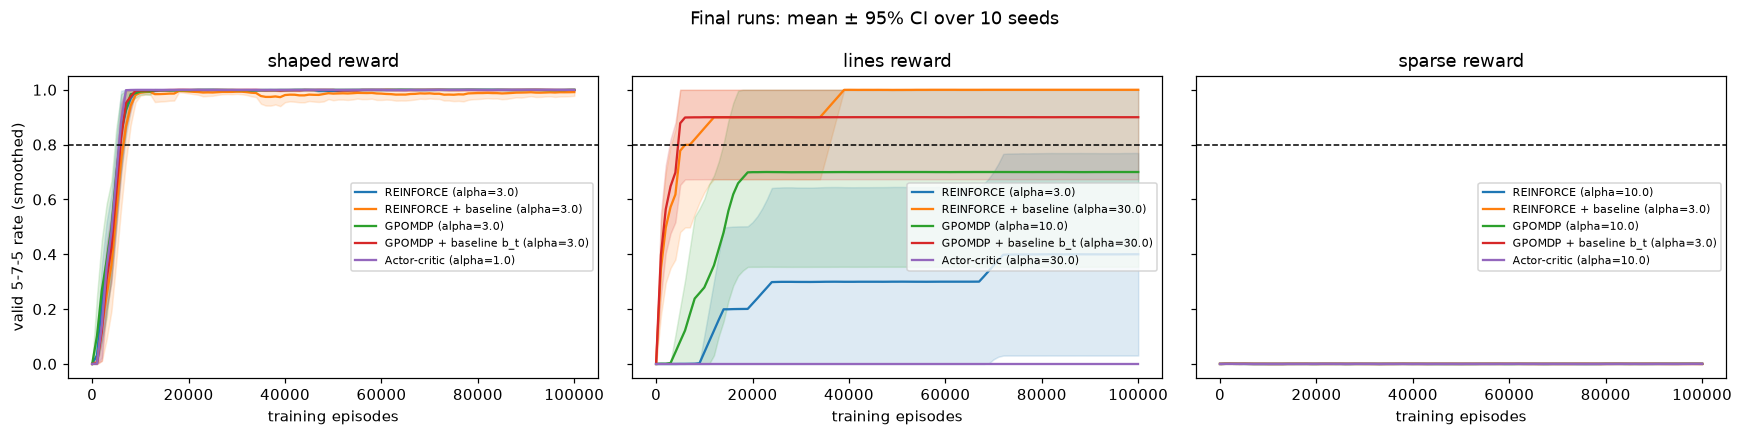

In [8]:
FINAL = {}
FINAL['shaped'] = X.run_many([P.spec(m, best['shaped'][m], s) for m in P.METHODS for s in P.FINAL_SEEDS],
                             X.RESULTS_DIR / '04_final.pkl')
for d in ['lines', 'sparse']:
    FINAL[d] = X.run_many([P.spec(m, best[d][m], s, reward=P.REWARD_DESIGNS[d]) for m in P.METHODS for s in P.FINAL_SEEDS],
                          X.RESULTS_DIR / '05_final.pkl')
final = {d: {m: FINAL[d][k * 10:(k + 1) * 10] for k, m in enumerate(P.METHODS)} for d in DESIGNS}

x = np.array(final['shaped']['gpomdp_b'][0]['history']['eval_episodes'])
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, d in zip(axes, DESIGNS):
    for m in P.METHODS:
        ys = np.array([P.smoothed(r['history'], 'valid') for r in final[d][m]])
        mean, hw = stats.mean_ci(ys)
        ax.plot(x, mean, color=COLORS[m], label=f'{LABELS[m]} (alpha={best[d][m]})')
        ax.fill_between(x, np.clip(mean - hw, 0, 1), np.clip(mean + hw, 0, 1), color=COLORS[m], alpha=0.15)
    ax.axhline(TARGET_VALID, color='k', ls='--', lw=1)
    ax.set_title(f'{d} reward'); ax.set_xlabel('training episodes'); ax.legend(fontsize=7, loc='center right')
axes[0].set_ylabel('valid 5-7-5 rate (smoothed)')
fig.suptitle(f'Final runs: mean ± 95% CI over {len(P.FINAL_SEEDS)} seeds')
plt.tight_layout(); plt.show()

In [9]:
print(f'Sample complexity: training episodes until the smoothed valid rate reaches {TARGET_VALID} ({len(P.FINAL_SEEDS)} seeds)')
print(f'{"method":24s}' + ''.join(f'{d:>34s}' for d in DESIGNS))
sc = {}
for m in P.METHODS:
    row = ''
    for d in DESIGNS:
        s = [P.sample_complexity(r['history'], TARGET_VALID, 'valid') for r in final[d][m]]
        sc[(d, m)] = s
        reached = [v for v in s if v is not None]
        if reached:
            mean, hw = stats.mean_ci(reached) if len(reached) > 1 else (reached[0], 0.0)
            cell = f'{len(reached):2d}/10  {mean:7,.0f} ± {hw:6,.0f} (a={best[d][m]})'
        else:
            cell = f' 0/10  never reached (a={best[d][m]})'
        row += f'{cell:>34s}'
    print(f'{LABELS[m]:24s}' + row)
print('(mean ± 95% CI over the runs that reached the target)')

print(f'\nDiversity of 200 fresh final poems, mean over seeds: share of distinct poems / share of the vocabulary used')
for m in P.METHODS:
    print(f'{LABELS[m]:24s}' + ''.join(f'{np.mean([r["final_metrics"]["distinct_poems"] for r in final[d][m]]):>27.3f} / '
                                       f'{np.mean([r["final_metrics"]["distinct_words"] for r in final[d][m]]):.3f}' for d in DESIGNS))

Sample complexity: training episodes until the smoothed valid rate reaches 0.8 (10 seeds)
method                                              shaped                             lines                            sparse
REINFORCE                  10/10    6,500 ±    695 (a=3.0)    4/10   30,750 ± 44,460 (a=3.0)      0/10  never reached (a=10.0)
REINFORCE + baseline       10/10    7,000 ±    954 (a=3.0)  10/10    9,100 ±  7,685 (a=30.0)       0/10  never reached (a=3.0)
GPOMDP                     10/10    6,100 ±    856 (a=3.0)   7/10   13,143 ±  4,253 (a=10.0)      0/10  never reached (a=10.0)
GPOMDP + baseline b_t      10/10    6,500 ±    773 (a=3.0)   9/10    4,889 ±    256 (a=30.0)       0/10  never reached (a=3.0)
Actor-critic               10/10    6,100 ±    406 (a=1.0)      0/10  never reached (a=30.0)      0/10  never reached (a=10.0)
(mean ± 95% CI over the runs that reached the target)

Diversity of 200 fresh final poems, mean over seeds: share of distinct poems / share of the v

Under the *lines* reward every run ends up writing **one poem**. The runs that miss the target are not slow, they are stuck: each one
writes a single poem with two exact lines and one wrong line, every time.

In [10]:
print('Lines reward: final runs that did not reach the target (final valid rate, exact lines, most frequent poem)')
for m in P.METHODS:
    for r, v in zip(final['lines'][m], sc[('lines', m)]):
        if v is None:
            f, top = r['final_metrics'], r['final_poems'][0]
            print(f"  {LABELS[m]:24s} seed {r['spec']['seed']}: valid {f['valid']:.2f}, return {f['return']:.2f} | {top[1]:3d}x {top[0]}")

Lines reward: final runs that did not reach the target (final valid rate, exact lines, most frequent poem)
  REINFORCE                seed 100: valid 0.00, return 2.00 | 200x what fate to the god (5) / is my house to our ships that he would (10) / while thus to the day (5)
  REINFORCE                seed 101: valid 0.00, return 2.00 | 200x with rage of the field (5) / that i was at the first his hand a goddess (11) / he said to the dead (5)
  REINFORCE                seed 102: valid 0.00, return 2.00 | 199x in a valiant foe (5) / and round and thy soft arms which she was before (11) / from the grecian train (5)
  REINFORCE                seed 104: valid 0.00, return 2.00 | 199x i am in the ground (5) / great ajax first they are you will be a (10) / what yet to the skies (5)
  REINFORCE                seed 105: valid 0.00, return 2.00 | 200x to his head his hands and heaven (8) / and a seat and the suitors (7) / but he had the skies (5)
  REINFORCE                seed 108: valid 0.00, r

## 4. What "learning" means under the sparse reward

Before the first valid poem, every sparse reward in a batch is zero, so **every estimator returns exactly zero** (with a leave-one-out
baseline too, since all returns are equal) and the policy does not move. The run is a random search with the bigram. Once a valid poem
appears, one update raises the logit of each of its actions by about $\alpha/n$ (the score of a softmax is $1-\pi(a\mid s)$ at the chosen
entry, and the poem's return 1 is divided by the batch size $n = 10$). At the tuned step sizes, α ≤ 10, that is at most one unit of
log-probability per action. The poem's probability grows, but from a tiny value, and most of its states (previous word, syllable count)
are not visited by any other poem, so the next success is still rare. The policy has to collect many lucky poems before it moves.

To check that the mechanism is "wait for a lucky poem, then memorise it", we run one extra, **off-protocol** experiment: the sparse reward
with α = 100 (outside the tuned grid, chosen because it learned in an exploratory run during development; that run is not kept), for the four batch methods and the same 10 final seeds.
If the mechanism is right, the sample complexity should be roughly the waiting time until the first success, which is geometric with
mean $1/P(\text{valid})$ under the bigram, plus a few thousand episodes of smoothing delay, and the learned policy should write one poem.

all 40 runs loaded from 05_sparse_large_step.pkl
sparse reward, alpha = 100.0
method                      first valid training poem     sample complexity (valid >= 0.8)
REINFORCE                [17460, 21130, 14330, 1950, 570, 9920, 11180, 16780, 5060, 31770]
                         [22000, 26000, 18000, 6000, 5000, 14000, 15000, 21000, 10000, 36000]
REINFORCE + baseline     [17460, 21130, 14330, 1950, 570, 9920, 11180, 16780, 5060, 31770]
                         [22000, 26000, 19000, 6000, 5000, 14000, 16000, 21000, 10000, 36000]
GPOMDP                   [17460, 21130, 14330, 1950, 570, 9920, 11180, 16780, 5060, 31770]
                         [22000, 26000, 18000, 6000, 5000, 14000, 15000, 21000, 10000, 36000]
GPOMDP + baseline b_t    [17460, 21130, 14330, 1950, 570, 9920, 11180, 16780, 5060, 31770]
                         [22000, 26000, 19000, 6000, 5000, 14000, 16000, 21000, 10000, 36000]


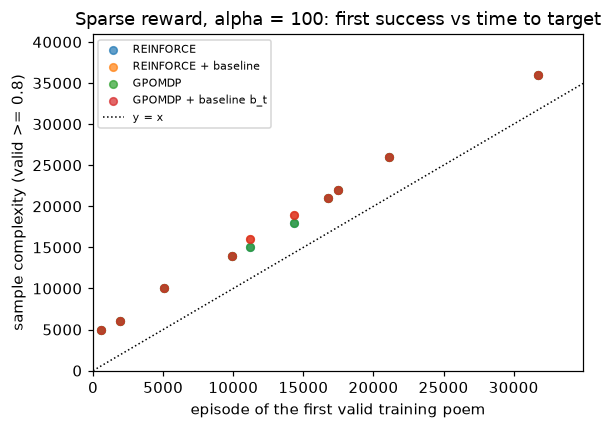


mean episode of the first success: 13,015 (10 seeds); expected under the bigram: 1 / P(valid) = 9,798
delay from the first success to the target (REINFORCE): 3,670 to 4,940 episodes


In [11]:
BIG = 100.0
large = X.run_many([P.spec(m, BIG, s, reward=P.REWARD_DESIGNS['sparse']) for m in P.METHODS[:4] for s in P.FINAL_SEEDS],
                   X.RESULTS_DIR / '05_sparse_large_step.pkl')
large = {m: large[k * 10:(k + 1) * 10] for k, m in enumerate(P.METHODS[:4])}

def first_success(h):
    tr = np.array(h['train_return'])
    hit = np.nonzero(tr > 0)[0]
    return h['train_episodes'][hit[0]] if len(hit) else None

fig, ax = plt.subplots(figsize=(5.5, 4))
print(f'sparse reward, alpha = {BIG}')
print(f'{"method":24s} {"first valid training poem":>28s} {"sample complexity (valid >= 0.8)":>36s}')
for m in P.METHODS[:4]:
    fs = [first_success(r['history']) for r in large[m]]
    scs = [P.sample_complexity(r['history'], TARGET_VALID, 'valid') for r in large[m]]
    print(f'{LABELS[m]:24s} {str([None if f is None else int(f) for f in fs])}')
    print(f'{"":24s} {str(scs)}')
    pts = [(f, v) for f, v in zip(fs, scs) if f is not None and v is not None]
    if pts:
        ax.scatter(*zip(*pts), color=COLORS[m], label=LABELS[m], s=25, alpha=0.7)
lim = 1.1 * max(max(first_success(r["history"]) for r in large[m]) for m in large)
ax.plot([0, lim], [0, lim], 'k:', lw=1, label='y = x')
ax.set_xlim(0, lim); ax.set_ylim(0, lim + 6000)
ax.set_xlabel('episode of the first valid training poem'); ax.set_ylabel('sample complexity (valid >= 0.8)')
ax.set_title(f'Sparse reward, alpha = {BIG:g}: first success vs time to target'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
fs = np.array([first_success(r['history']) for r in large['reinforce']], float)
delay = np.array([P.sample_complexity(r['history'], TARGET_VALID, 'valid') for r in large['reinforce']]) - fs
print(f'\nmean episode of the first success: {fs.mean():,.0f} (10 seeds); expected under the bigram: 1 / P(valid) = {1 / p_valid:,.0f}')
print(f'delay from the first success to the target (REINFORCE): {delay.min():,.0f} to {delay.max():,.0f} episodes')

In [12]:
print(f'Sparse reward, alpha = {BIG:g}: final poems of the first two seeds of each method')
for m in P.METHODS[:4]:
    for r in large[m][:2]:
        top = r['final_poems'][0]
        print(f"  {LABELS[m]:24s} seed {r['spec']['seed']}: {len(r['final_poems']):3d} distinct | {top[1]:3d}x {top[0]}")

Sparse reward, alpha = 100: final poems of the first two seeds of each method
  REINFORCE                seed 100:   1 distinct | 200x he had told his room (5) / full last to shield he went home (7) / it bore by the host (5)
  REINFORCE                seed 101:   1 distinct | 200x or do so heaven (5) / troy the same time but old friend (7) / to the wife suitors (5)
  REINFORCE + baseline     seed 100:   1 distinct | 200x he had told dear fear (5) / full last to shield he went home (7) / it in the youth days (5)
  REINFORCE + baseline     seed 101:   1 distinct | 200x or do so heaven (5) / troy the same time but old friend (7) / to the wife suitors (5)
  GPOMDP                   seed 100:   1 distinct | 200x he had told his room (5) / full last to shield he went home (7) / it bore by the host (5)
  GPOMDP                   seed 101:   1 distinct | 200x or do so heaven (5) / troy the same time but old friend (7) / to the wife suitors (5)
  GPOMDP + baseline b_t    seed 100:   1 distinct 

## 5. Discussion

**Sparse reward: within the protocol, nothing learns.** Under the bigram, a valid 5-7-5 poem appears about once every 9 800 episodes
(§1). Before the first success every gradient estimate is exactly zero. After it, a step of α ≤ 10 is too small to make the next
success likely (§4). So no method reaches the target in any tuning or final run, and the tuning scores are 0.000 at every α. The "best"
α values in the table are arbitrary among ties, and the final sparse runs end with 100% distinct poems, which is still the bigram's
diversity. The off-protocol runs with α = 100 do reach the target, 10/10 for every batch method, but only through a lottery:
- The run waits for the first valid poem (mean episode 13 015 over 10 seeds; the geometric waiting time has mean and standard deviation
  9 800, so this is consistent).
- One step then memorises that poem, and the smoothed valid rate crosses 0.8 about 3 700–4 900 episodes later. That delay is mostly the
  5-evaluation smoothing window.
- The learned policy writes that single poem 200 times out of 200.
The sample complexity is set by the bigram's success probability, and no estimator changes it. For that reason the four batch methods
have the same first-success episode in every seed.

**GPOMDP = REINFORCE under a terminal reward, exactly.** The derivation in §2 is confirmed three ways:
- the two gradients differ by exactly 0 on the same batches under the sparse reward, but by up to 1.19 (shaped) and 0.39 (lines);
- the variance ratio is 1.00× under the sparse reward;
- the training runs are identical in 21/21 (α, seed) pairs under the sparse reward and in 0/21 under *lines*. The α = 100 runs also
  give the same sample complexity for REINFORCE and GPOMDP in every seed.

GPOMDP's advantage comes from dropping rewards that arrive *before* an action. A reward paid only at the end leaves
nothing to drop.

**Baselines can increase variance.** At the partially trained policy (73% valid poems), the leave-one-out baselines make the variance
4.4× (REINFORCE + b) and 4.2× (GPOMDP + b_t) larger under the sparse reward, and under the shaped reward 1.7× (GPOMDP + b_t) and 1.06×
(REINFORCE + b) larger. A constant baseline reduces variance only when the size of the score does not depend much on the return. Here it depends on it
strongly: the valid poems are the ones the policy has already learned, so their actions have π ≈ 1 and their score is small (mean
squared norm 0.43). The invalid poems contain unlikely actions with large scores (8.29). Without a baseline, the invalid poems
contribute nothing to the sparse gradient. With a baseline of about 0.7, they contribute $-0.7\times$ their large score. Under *lines*,
where a near-miss still earns 2 of the 4 points, all three variance reductions do occur (0.39–0.74×). This is only one policy.
Notebook 06 measures the variances at fixed points more carefully, including an untrained policy.

**Lines reward: the baselines decide whether the run succeeds.** With three exact-line bonuses the problem is learnable:
- GPOMDP + b_t reaches the target in 9/10 runs at 4 900 ± 300 episodes, faster than with the shaped reward (6 500);
- REINFORCE + b reaches it in 10/10, but with a long tail (9 100 ± 7 700);
- GPOMDP without a baseline reaches it in 7/10 (13 100), REINFORCE in 4/10 (30 800), and the actor-critic in 0/10.

Every run that misses the target is stuck rather than slow: it writes **one** poem with two exact lines and one wrong line, every time.
The *lines* reward is non-negative, so without a baseline every sampled poem is pushed up, including the near-misses. Once one of them
dominates, the policy stops exploring and the line that is wrong never gets a learning signal. A baseline pushes *below-average* poems
down, so near-misses are discouraged while better poems are still being sampled. This is the same "rich get richer" collapse seen
for the no-baseline methods at α = 1 in notebook 04. The shaped design avoided it with the KL term to the bigram (η = 0.5), which keeps
the policy stochastic, and the *lines* reward has no KL term. The two best methods also tolerate a 3–10× larger step size (best α = 30,
against 3 and 10 without a baseline).

**The actor-critic fails with both sparse designs.** Its tuning score is flat (1.65) for every α ≥ 3, and in 9 of its 10 final runs it locks in
two exact lines and one line cut to 1–3 syllables (the 7-syllable line in 6 of them). In the tenth run, two lines are cut. Its policy step uses the TD error $r + V(s') - V(s)$, so
the bonus at a line end reaches a word $k$ steps earlier only after the critic has propagated it back through $k$ tabular states. Most
states (previous word, syllable count) are visited too rarely for that to happen before the policy collapses. With the shaped reward the
per-word progress term gives the critic an immediate signal, and the actor-critic is as fast as the batch methods (6 100). We have not
isolated why the collapse favours *short* lines in particular.

**Summary for the project's question.** Making the sparse goal feasible required *both* intermediate rewards *and* a variance-reducing
baseline:
- with the terminal reward only, sample complexity is a waiting time for luck;
- with line-level rewards the baselined methods learn, at least as fast as with the fully shaped reward, but every run ends on a single
  memorised poem, because nothing in that reward asks for diversity;
- the fully shaped reward with its KL term is the only design that is reliable for all five methods.